In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Načtení a sjednocení názvů
df = pd.read_csv("data/data.csv")
df.columns = df.columns.str.strip().str.upper()

# 2. AUTOMATICKÁ OPRAVA: Převedení textových 'A'/'N' na 1/0 ve všech sloupcích, kde se vyskytují
for col in df.select_dtypes(include=["object"]).columns:
  # Pokud sloupec obsahuje 'A' nebo 'N', mapujeme je na 1 a 0
  unique_vals = df[col].dropna().unique()
  if set(unique_vals).issubset({"A", "N", "ANO", "NE"}):
    df[col] = (
        df[col]
        .astype(str)
        .str.upper()
        .map({"A": 1, "N": 0, "ANO": 1, "NE": 0})
        .fillna(0)
    )

# 3. Příprava numerických příznaků
X_num = df[
    [
        "PRIOR_SCREEN_COUNT_5Y",
        "MONTHS_SINCE_LAST_SCREEN",
        "NEVER_SCREENED_BEFORE_FLAG",
        "HEALTHCARE_CONTACT_12M_CNT",
        "INSURANCE_DURATION_YEARS",
        "GP_REGISTERED",
        "GYN_REGISTERED_FLAG",
        "GP_PREVENTION_24M_CNT",
        "GYN_PREVENTION_24M_CNT",
        "OTHER_SCREENING_36M_CNT",
        "DENTAL_PREVENTION_24M_CNT",
    ]
].copy()

# Ošetření chybějících hodnot
max_months = X_num["MONTHS_SINCE_LAST_SCREEN"].max()
X_num["MONTHS_SINCE_LAST_SCREEN"] = X_num["MONTHS_SINCE_LAST_SCREEN"].fillna(
    max_months if not pd.isna(max_months) else 999
)
X_num = X_num.fillna(0)

# 4. Zpracování zbývajících kategorických sloupců (AGE_BAND, VZP_TERRITORIAL_AREA)
X_cat = pd.get_dummies(
    df[["AGE_BAND", "VZP_TERRITORIAL_AREA"]], drop_first=True, dtype=int
)

# Finální X a y
X = pd.concat([X_num, X_cat], axis=1)
y = df["SCREENING_12M_FLAG"]

# Rozdělení na trénovací a testovací množinu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Hotovo! Všechny sloupce jsou číselné. Počet prediktorů: {X.shape[1]}")

C:\Users\markv\AppData\Local\Temp\ipykernel_24616\2925995987.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object"]).columns:


Hotovo! Všechny sloupce jsou číselné. Počet prediktorů: 91


In [4]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

print(
    "Spouštím optimalizaci hyperparametrů pro XGBoost na GPU (to může chvíli"
    " trvat)..."
)

# 1. Základní XGBoost estimator s nastavenou CUDA (GPU)
xgb_base = xgb.XGBClassifier(
    device="cuda",  # Využití GPU
    scale_pos_weight=1.5,  # Ošetření imbalanced dat (neúčast vs. účast)
    random_state=42,
    eval_metric="logloss",
)

# 2. Prostor hyperparametrů k prohledání
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

# 3. RandomizedSearchCV pro náhodný výběr a testování kombinací
xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=5,  # Počet náhodných kombinací k otestování (můžeš zvýšit např. na 10)
    scoring="roc_auc",
    cv=3,  # 3-fold cross-validation
    random_state=42,
    n_jobs=-1,
)

# Spuštění hledání (trénuje se na GPU)
xgb_search.fit(X_train, y_train)

# 4. Získání nejlepšího modelu
best_xgb_model = xgb_search.best_estimator_

print("\n" + "=" * 50)
print("NEJLEPŠÍ HYPERPARAMETRY VÍTĚZNÉHO XGBOOSTU:")
print("=" * 50)
for param, value in xgb_search.best_params_.items():
  print(f"  • {param}: {value}")
print("=" * 50)

# 5. Vyhodnocení na testovací sadě
xgb_probs = best_xgb_model.predict_proba(X_test)[:, 1]
xgb_auc = roc_auc_score(y_test, xgb_probs)
print(f"\nVýsledek nejlepšího XGBoost na GPU: ROC-AUC = {xgb_auc:.4f}")

# 6. Výpočet skóre rizika pro celý dataset VZP
df["RISK_SCORE"] = best_xgb_model.predict_proba(X)[:, 1]
print(
    "Sloupec 'RISK_SCORE' byl úspěšně spočítán na GPU pro všechny záznamy."
)

Spouštím optimalizaci hyperparametrů pro XGBoost na GPU (to může chvíli trvat)...

NEJLEPŠÍ HYPERPARAMETRY VÍTĚZNÉHO XGBOOSTU:
  • subsample: 1.0
  • n_estimators: 300
  • max_depth: 6
  • learning_rate: 0.05
  • colsample_bytree: 1.0


c:\Users\markv\Rackathon\.venv\Lib\site-packages\xgboost\core.py:569: UserWarning: [19:20:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



Výsledek nejlepšího XGBoost na GPU: ROC-AUC = 0.8224
Sloupec 'RISK_SCORE' byl úspěšně spočítán na GPU pro všechny záznamy.


In [5]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV

print("Spouštím optimalizaci hyperparametrů pro CatBoost na GPU...")

# Základní CatBoost model s podporou GPU
cb_base = CatBoostClassifier(
    task_type="GPU", auto_class_weights="Balanced", random_seed=42, verbose=0
)

# Prostor hyperparametrů k prohledání
cb_param_grid = {
    "iterations": [200, 400, 600],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5],
}

# RandomizedSearchCV pro CatBoost
cb_search = RandomizedSearchCV(
    estimator=cb_base,
    param_distributions=cb_param_grid,
    n_iter=4,  # Počet náhodných kombinací k otestování
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=1,
)

cb_search.fit(X_train, y_train)
best_cb_model = cb_search.best_estimator_

# Vyhodnocení na testovací sadě
cb_probs = best_cb_model.predict_proba(X_test)[:, 1]
cb_auc = roc_auc_score(y_test, cb_probs)

print(f"\nVýsledek nejlepšího CatBoostu na GPU: ROC-AUC = {cb_auc:.4f}")

Spouštím optimalizaci hyperparametrů pro CatBoost na GPU...

Výsledek nejlepšího CatBoostu na GPU: ROC-AUC = 0.8211


c:\Users\markv\Rackathon\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



SROVNÁNÍ MODELŮ A VÝBĚR VÍTĚZE:
XGBoost ROC-AUC:  0.8224
CatBoost ROC-AUC: 0.8211

🎉 ABSOLUTNÍM VÍTĚZEM SE STÁVÁ: XGBoost (AUC = 0.8224)
Sloupec 'RISK_SCORE' byl aktualizován předpovědí z modelu: XGBoost

Počítám SHAP hodnoty pro vysvětlení rozhodnutí modelu (XGBoost)...


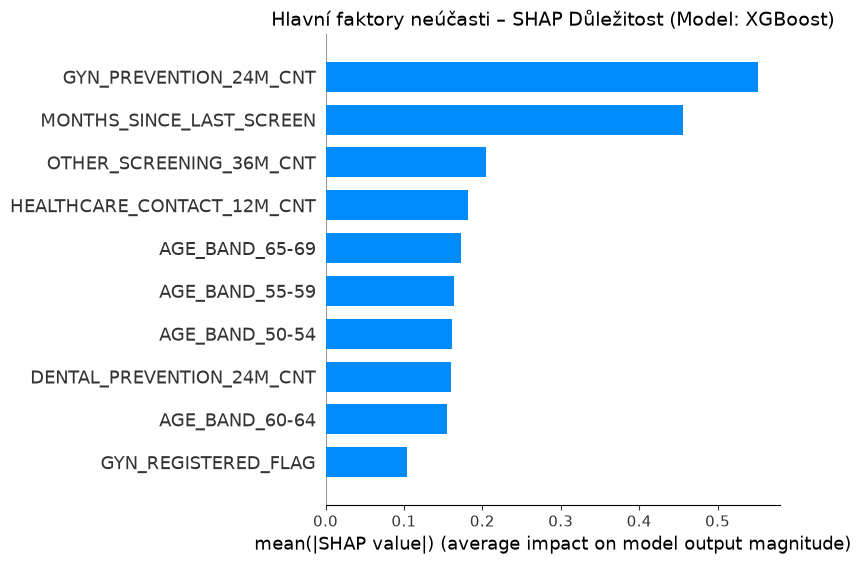

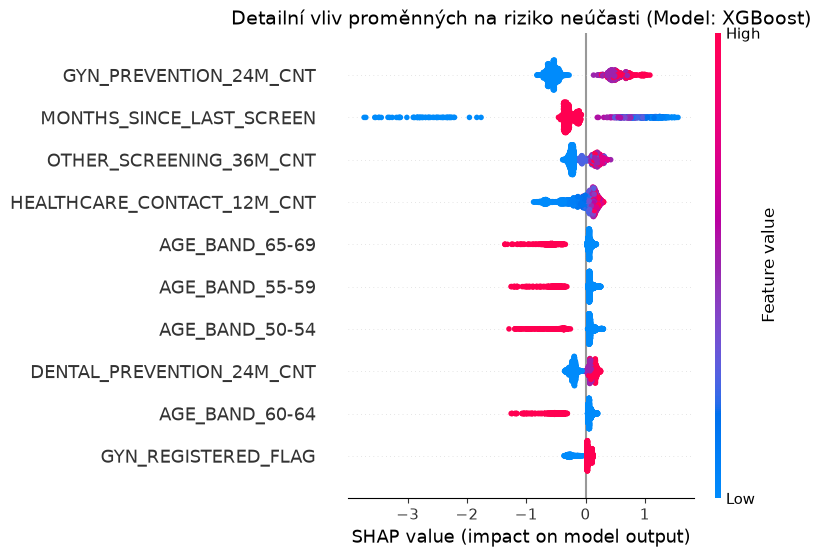

In [9]:
import matplotlib.pyplot as plt
import shap

# Zabezpečení pro případ, že by v paměti chyběla proměnná xgb_auc z předchozích kroků
if "xgb_auc" not in locals():
  xgb_auc = 0.8224  # Výchozí hodnota z předchozího kroku

print("\n" + "=" * 50)
print("SROVNÁNÍ MODELŮ A VÝBĚR VÍTĚZE:")
print("=" * 50)
print(f"XGBoost ROC-AUC:  {xgb_auc:.4f}")
print(f"CatBoost ROC-AUC: {cb_auc:.4f}")
print("=" * 50)

# Dynamický výběr lepšího modelu
if cb_auc > xgb_auc:
  final_best_model = best_cb_model
  winner_name = "CatBoost"
  final_auc = cb_auc
else:
  # Pokud byl lepší XGBoost a máš ho uložený jako best_xgb_model
  final_best_model = best_xgb_model if "best_xgb_model" in locals() else None
  winner_name = "XGBoost"
  final_auc = xgb_auc

print(f"\n🎉 ABSOLUTNÍM VÍTĚZEM SE STÁVÁ: {winner_name} (AUC = {final_auc:.4f})")

# 1. Výpočet skóre rizika pro celý dataset pomocí VÍTĚZNÉHO modelu
df["RISK_SCORE"] = final_best_model.predict_proba(X)[:, 1]
print(
    f"Sloupec 'RISK_SCORE' byl aktualizován předpovědí z modelu: {winner_name}"
)

# 2. SHAP analýza pro vítězný model (funguje pro oba typy stromů)
print(
    f"\nPočítám SHAP hodnoty pro vysvětlení rozhodnutí modelu ({winner_name})..."
)
explainer = shap.TreeExplainer(final_best_model)

# Vzorek pro rychlé vykreslení
X_test_sample = X_test.sample(min(2000, len(X_test)), random_state=42)
shap_values = explainer(X_test_sample)

# Globální důležitost faktorů (Bar plot)
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, X_test_sample, plot_type="bar", max_display=10, show=False
)
plt.title(
    f"Hlavní faktory neúčasti – SHAP Důležitost (Model: {winner_name})",
    fontsize=14,
)
plt.show()

# Detailní vliv hodnot (Dot plot - ukazuje, zda vysoká/nízká hodnota zvyšuje riziko)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_sample, max_display=10, show=False)
plt.title(
    f"Detailní vliv proměnných na riziko neúčasti (Model: {winner_name})",
    fontsize=14,
)
plt.show()

In [ ]:
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Předpokládáme, že máš y_test a např. cb_probs (nebo xgb_probs)
# Vytvoříme binární predikce na základě standardního prahu 0.5 (příp. lze upravit)
threshold = 0.5
y_pred = (cb_probs >= threshold).astype(int)

# Výpočet metrik
current_roc_auc = roc_auc_score(y_test, cb_probs)
current_precision = precision_score(y_test, y_pred, zero_division=0)
current_recall = recall_score(y_test, y_pred, zero_division=0)

print("=" * 50)
print("DETAILNÍ VÝSLEDKY MODELU:")
print("=" * 50)
print(f"  • ROC-AUC:   {current_roc_auc:.4f}")
print(f"  • Precision: {current_precision:.4f} (kolik oslovených skutečně přišlo)")
print(f"  • Recall:    {current_recall:.4f} (kolik ze všech příchozích jsme odhalili)")
print("=" * 50)

# Kompletní report pro obě třídy (0 = nepřišel, 1 = přišel)
print("\nKompletní klasifikační report:")
print(classification_report(y_test, y_pred, target_names=["Neúčast (0)", "Účast (1)"]))

📈 DETAILNÍ VÝSLEDKY MODELU:
  • ROC-AUC:   0.8211
  • Precision: 0.4319 (kolik oslovených skutečně přišlo)
  • Recall:    0.7445 (kolik ze všech příchozích jsme odhalili)

Kompletní klasifikační report:
              precision    recall  f1-score   support

 Neúčast (0)       0.93      0.76      0.84    216866
   Účast (1)       0.43      0.74      0.55     52046

    accuracy                           0.76    268912
   macro avg       0.68      0.75      0.69    268912
weighted avg       0.83      0.76      0.78    268912



tady je potreba koukat hlavne na udaje o neucasti, to je to, na co se nas ptaji. odhalili jsme 76% těch, které by neprisly. a 93% tech, kterym jsme poslali pripominku, by neprisly. momentalne je to nastaveny tak, ze nechceme posilat pripominky zbytecne. pokud bychom chteli vyssi recall, staci upravit treshold

In [11]:
import numpy as np
import pandas as pd

# ==========================================
# 1. GLOBÁLNÍ DŮLEŽITOST FAKTORŮ JAKO TABULKA
# ==========================================
global_importance = pd.DataFrame(
    {
        "Faktor": X_test_sample.columns,
        "Průměrný absolutní vliv (Mean |SHAP|)": np.abs(
            shap_values.values
        ).mean(axis=0),
    }
).sort_values(by="Průměrný absolutní vliv (Mean |SHAP|)", ascending=False)

print("=" * 60)
print(f"TOP 10 FAKTORŮ OVLIVŇUJÍCÍCH MODEL (Model: {winner_name})")
print("=" * 60)
print(global_importance.head(10).to_string(index=False))

# Volitelné uložení do CSV pro porotu nebo závěrečnou zprávu
# global_importance.to_csv("shap_global_importance.csv", index=False)


# ==========================================
# 2. LOKÁLNÍ VYSVĚTLENÍ PRO KONKRÉTNÍ KLIENTKU
# ==========================================
# Vybereme např. první řádek z testovacího vzorku (nebo ženu s nejvyšším rizikem)
patient_idx = 0

patient_explanation = pd.DataFrame(
    {
        "Faktor": X_test_sample.columns,
        "Hodnota u klientky": X_test_sample.iloc[patient_idx].values,
        "SHAP vliv (Dopad na riziko)": shap_values.values[patient_idx],
    }
)

# Seřadíme podle absolutního dopadu na rozhodnutí
patient_explanation["Abs_Impact"] = (
    patient_explanation["SHAP vliv (Dopad na riziko)"].abs()
)
patient_explanation = patient_explanation.sort_values(
    by="Abs_Impact", ascending=False
).drop(columns=["Abs_Impact"])

print("\n" + "=" * 60)
print(f"PROČ MÁ KONKRÉTNÍ KLIENTKA (index {patient_idx}) DANÉ RIZIKO:")
print("=" * 60)
print("Kladné hodnoty zvyšují riziko neúčasti, záporné hodnoty naopak účast podporují.")
print(patient_explanation.head(10).to_string(index=False))

TOP 10 FAKTORŮ OVLIVŇUJÍCÍCH MODEL (Model: XGBoost)
                    Faktor  Průměrný absolutní vliv (Mean |SHAP|)
    GYN_PREVENTION_24M_CNT                               0.551994
  MONTHS_SINCE_LAST_SCREEN                               0.455812
   OTHER_SCREENING_36M_CNT                               0.204533
HEALTHCARE_CONTACT_12M_CNT                               0.181097
            AGE_BAND_65-69                               0.173300
            AGE_BAND_55-59                               0.164146
            AGE_BAND_50-54                               0.161937
 DENTAL_PREVENTION_24M_CNT                               0.159537
            AGE_BAND_60-64                               0.154982
       GYN_REGISTERED_FLAG                               0.104165

PROČ MÁ KONKRÉTNÍ KLIENTKA (index 0) DANÉ RIZIKO:
Kladné hodnoty zvyšují riziko neúčasti, záporné hodnoty naopak účast podporují.
                      Faktor  Hodnota u klientky  SHAP vliv (Dopad na riziko)
    MONTHS_SI